In [39]:
%pip install numpy matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [40]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [41]:
def ShowImage(image):
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.show()

## 1) Dilatacion

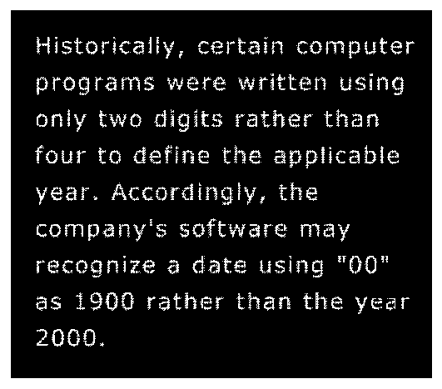

In [42]:
originalText = Image.open("Broken_Text.tif")
ShowImage(originalText)

In [43]:
# Load structural element
structuralElement = np.array([[0, 1, 0],
                              [1, 1, 1],
                              [0, 1, 0]], dtype=np.uint8)
print("Structural Element:")
print(structuralElement)

Structural Element:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


In [44]:
def dilate(image, struct_elem):
    img_height, img_width = image.shape
    se_height, se_width = struct_elem.shape
    
    pad_height = se_height // 2
    pad_width = se_width // 2
    
    # Pad the image with zeros to avoid boundary issues
    padded_image = np.pad(image, ((pad_height, pad_height), (pad_width, pad_width)), mode='constant', constant_values=0)
    
    dilated_image = np.zeros_like(padded_image)
    
    # Perform dilation
    for i in range(img_height):
        for j in range(img_width):
            if (image[i, j] == 1):
                dilated_image[i+pad_height, j+pad_width] = 1
                for m in range(se_height):
                    for n in range(se_width):
                        if struct_elem[m, n] == 1:
                            dilated_image[i + m, j + n] = 1

    #return original sized image
    dilated_image = dilated_image[pad_height:pad_height + img_height, pad_width:pad_width + img_width]
    
    return dilated_image

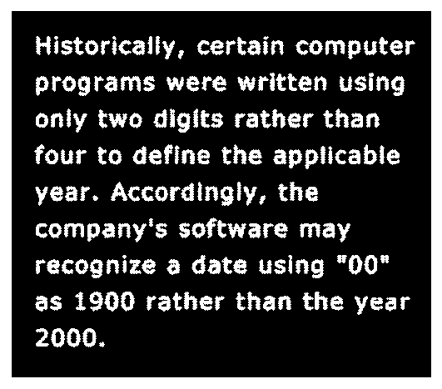

In [45]:
dilated_image = dilate(np.array(originalText), structuralElement)
ShowImage(dilated_image)

## 2) Erosion

In [46]:
def erode(image, struct_elem):
    img_height, img_width = image.shape
    se_height, se_width = struct_elem.shape
    
    pad_height = se_height // 2
    pad_width = se_width // 2
    
    # Pad the image with zeros to avoid boundary issues
    padded_image = np.pad(image, ((pad_height, pad_height), (pad_width, pad_width)), mode='constant', constant_values=0)
    
    eroded_image = np.zeros_like(padded_image)
    
    # Perform erosion
    for i in range(img_height):
        for j in range(img_width):
            if (image[i, j] != 0):
                match = True
                for m in range(se_height):
                    for n in range(se_width):
                        if struct_elem[m, n] == 1 and padded_image[i + m - pad_height, j + n - pad_width] == 0:
                            match = False
                            break
                if match:
                    eroded_image[i + pad_height, j + pad_width] = 1
    
    return eroded_image

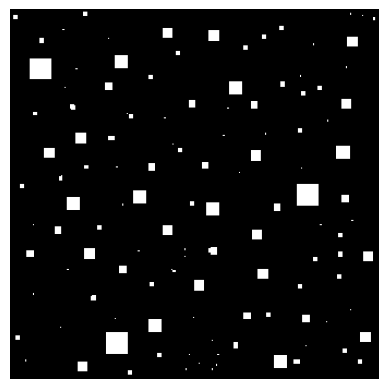

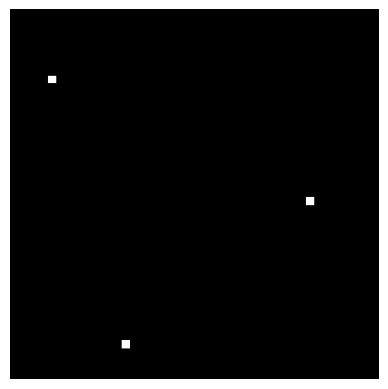

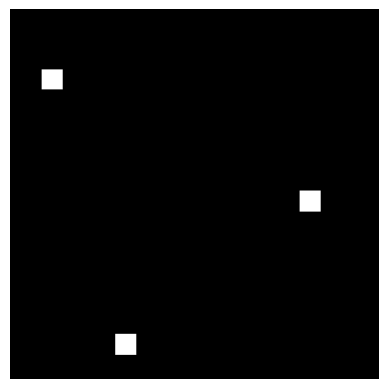

In [47]:
image2 = Image.open("Noisy_Squares.tif")
ShowImage(image2)
structuralElement2 = np.ones((13, 13), dtype=np.uint8)
eroded_image = erode(np.array(image2), structuralElement2)
ShowImage(eroded_image)
dilated_image2 = dilate(eroded_image, structuralElement2)
ShowImage(dilated_image2)

## 3) Apertura

In [48]:
def aperture(image, struct_elem):
    eroded = erode(image, struct_elem)
    opened = dilate(eroded, struct_elem)
    return opened

In [49]:
def closure(image, struct_elem):
    dilated = dilate(image, struct_elem)
    closed = erode(dilated, struct_elem)
    return closed

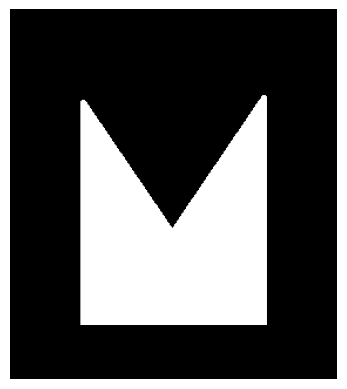

In [50]:
figure_b = Image.open("figure_B.bmp")
# To black and white
figure_b = figure_b.convert("1")
ShowImage(figure_b)

In [51]:
# Circle shaped structural element
def create_circle_struct_elem(radius):
    size = radius * 2 + 1
    struct_elem = np.zeros((size, size), dtype=np.uint8)
    center = radius
    
    for i in range(size):
        for j in range(size):
            if (i - center) ** 2 + (j - center) ** 2 <= radius ** 2:
                struct_elem[i, j] = 1
                
    return struct_elem

In [52]:
RADIUS = 15

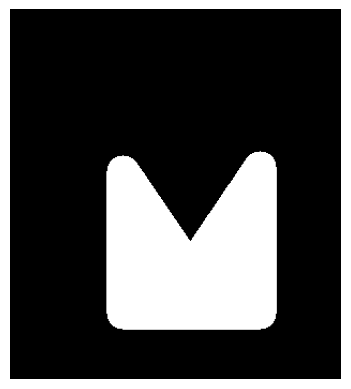

In [53]:
circle_struct_elem = create_circle_struct_elem(RADIUS)
aperture_result = aperture(np.array(figure_b), circle_struct_elem)
ShowImage(aperture_result)

In [54]:
def subtract_images(image1, image2):
    return np.clip(image1 ^ image2, 0, 255)

## 4) Extracción de borde

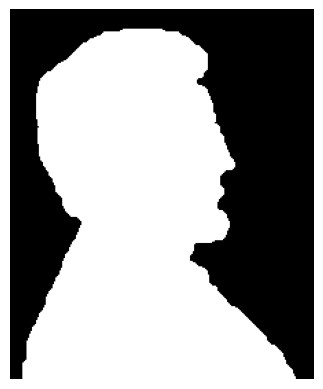

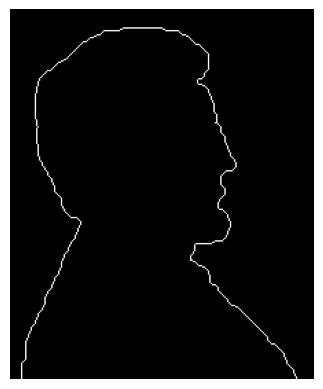

In [55]:
lincoln_image = Image.open("Lincoln from Penny.tif")
ShowImage(lincoln_image)
edge = subtract_images(np.array(lincoln_image), dilate(np.array(lincoln_image), structuralElement))
ShowImage(edge)

# 5) Thinning, Thickening, Top-hat y Hit-or-miss

Las cuatro operaciones se construyen a partir de erosión/dilatación. Para poder trabajar con elementos estructurales grandes y con imágenes en escala de grises, abajo se definen versiones vectorizadas (con `sliding_window_view`) de la erosión y dilatación, que funcionan tanto para imágenes binarias como de grises (erosión = mínimo en la vecindad, dilatación = máximo).

In [56]:
from numpy.lib.stride_tricks import sliding_window_view

def _windows(image, se_shape, pad_value):
    # Returns a (H, W, h, w) view with the neighbourhood of every pixel
    h, w = se_shape
    padded = np.pad(image, ((h // 2, h - 1 - h // 2), (w // 2, w - 1 - w // 2)),
                    mode='constant', constant_values=pad_value)
    return sliding_window_view(padded, se_shape)

def gray_erode(image, se):
    # Minimum over the pixels where se == 1 (border padded with max so it does not erode)
    return _windows(image, se.shape, image.max())[..., se.astype(bool)].min(axis=-1)

def gray_dilate(image, se):
    # Maximum over the pixels where se == 1
    return _windows(image, se.shape, image.min())[..., se.astype(bool)].max(axis=-1)

def gray_open(image, se):
    return gray_dilate(gray_erode(image, se), se)

def gray_close(image, se):
    return gray_erode(gray_dilate(image, se), se)

def show_row(images, titles, size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## d) Hit-or-miss

La transformada *hit-or-miss* (acierto o fallo) detecta **una forma o patrón exacto** de píxeles. Usa un par de elementos estructurales: $B_1$, que debe caer completamente sobre el objeto, y $B_2$, que debe caer completamente sobre el fondo:

$$A \circledast B = (A \ominus B_1) \cap (A^c \ominus B_2)$$

En la práctica se codifican ambos en una sola matriz: `1` = tiene que ser objeto, `0` = tiene que ser fondo, `-1` = no importa. El resultado vale 1 solo en los píxeles donde la vecindad coincide exactamente con el patrón. Se va primero porque thinning y thickening se definen a partir de ella.

In [57]:
def hit_or_miss(image, se):
    # se: 1 -> must be foreground, 0 -> must be background, -1 -> don't care
    A = np.asarray(image) > 0
    windows = _windows(A, se.shape, False)          # outside the image counts as background
    fits_foreground = np.all(windows[..., se == 1], axis=-1)     # A erode B1
    fits_background = ~np.any(windows[..., se == 0], axis=-1)    # A^c erode B2
    return fits_foreground & fits_background

**Ejemplo 1:** en la imagen de cuadrados del punto 2 se buscan los cuadrados de cada tamaño por separado. Para un cuadrado de lado $n$ el patrón es un bloque de $n \times n$ unos rodeado por un anillo de ceros (matriz de $(n+2) \times (n+2)$). El hit-or-miss marca solamente el centro de los cuadrados que tienen exactamente ese tamaño: a diferencia de la erosión, que también se activa con los cuadrados más grandes, acá un cuadrado de 7x7 no se detecta con el patrón de 4x4.

Nota: aunque el enunciado dice que los cuadrados miden 1, 3, 5, 7, 9 y 15 píxeles, en el archivo `Noisy_Squares.tif` la imagen está reescalada y los lados reales (medidos sobre la imagen) son 1, 4, 7, 9, 12 y 20 píxeles, así que se usan esos tamaños. Los cuadrados que tocan el borde o a otro cuadrado no se detectan, porque no tienen el anillo de fondo completo.

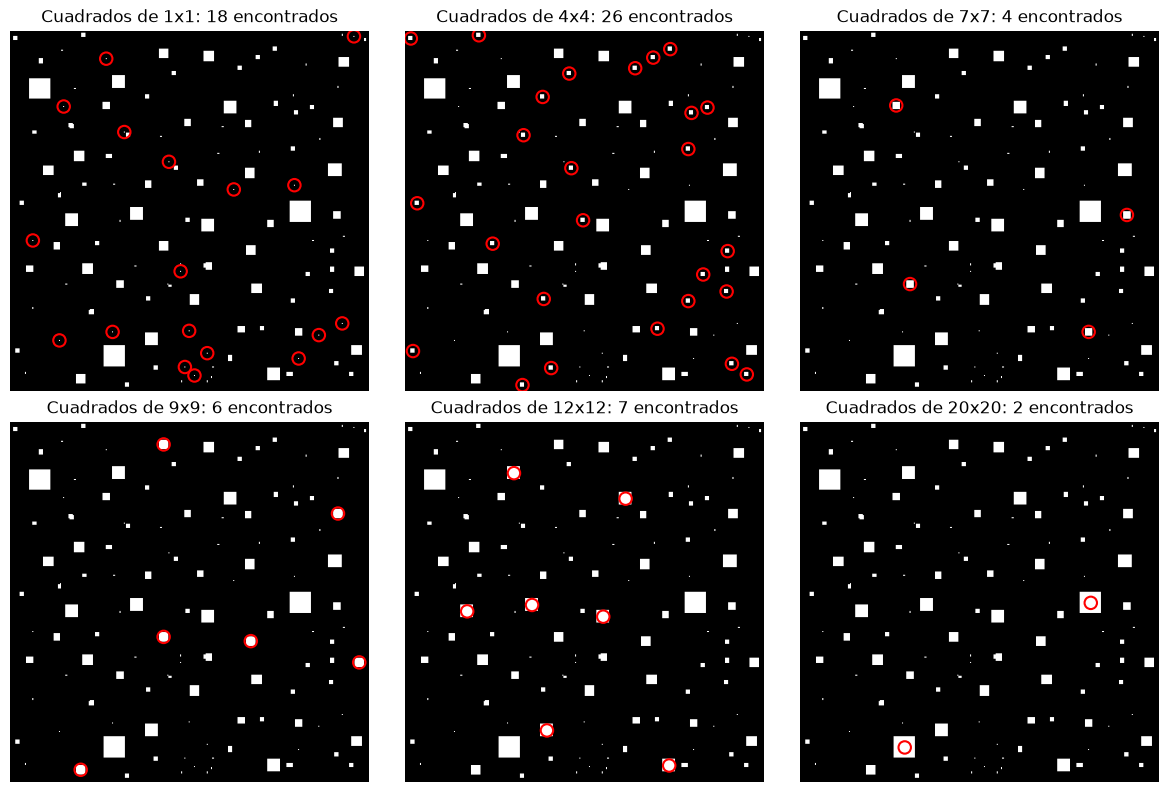

In [58]:
def square_pattern(n):
    se = np.zeros((n + 2, n + 2), dtype=int)
    se[1:-1, 1:-1] = 1
    return se

squares = np.array(Image.open("Noisy_Squares.tif")) > 0
# Real side lengths present in the file (the image is resampled, so they are not 1,3,5,7,9,15)
sizes = [1, 4, 7, 9, 12, 20]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, n in zip(axes.ravel(), sizes):
    hits = hit_or_miss(squares, square_pattern(n))
    ys, xs = np.nonzero(hits)
    ax.imshow(squares, cmap='gray')
    ax.scatter(xs, ys, s=80, facecolors='none', edgecolors='red', linewidths=1.5)
    ax.set_title(f"Cuadrados de {n}x{n}: {hits.sum()} encontrados")
    ax.axis('off')
plt.tight_layout()
plt.show()

**Ejemplo 2:** detección de esquinas. El patrón de abajo pide objeto a la derecha y abajo del píxel, y fondo arriba y a la izquierda, es decir una esquina superior izquierda. Rotando el patrón 90° se obtienen las otras tres esquinas.

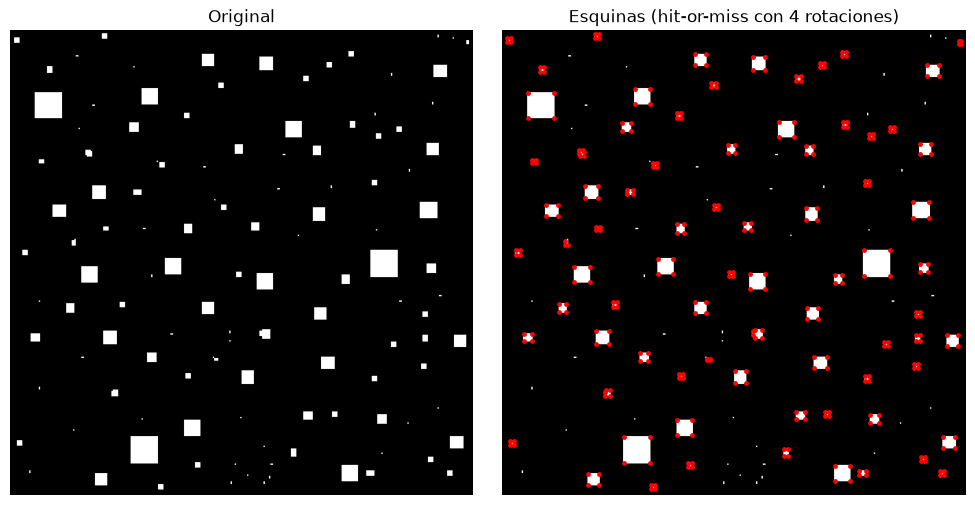

In [59]:
corner_tl = np.array([[-1,  0, -1],
                      [ 0,  1,  1],
                      [-1,  1, -1]])

corners = np.zeros_like(squares)
for k in range(4):
    corners |= hit_or_miss(squares, np.rot90(corner_tl, k))

ys, xs = np.nonzero(corners)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(squares, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(squares, cmap='gray'); axes[1].scatter(xs, ys, s=6, c='red')
axes[1].set_title("Esquinas (hit-or-miss con 4 rotaciones)"); axes[1].axis('off')
plt.tight_layout()
plt.show()

## a) Thinning

El *thinning* elimina del objeto los píxeles de borde que coinciden con un patrón hit-or-miss:

$$A \otimes B = A - (A \circledast B)$$

Se aplica en secuencia con una familia de elementos estructurales $\{B^1, \dots, B^8\}$ (el patrón base y sus rotaciones), y se repite hasta que la imagen deja de cambiar. Los patrones están diseñados para borrar únicamente píxeles de borde cuya eliminación no rompe la conectividad, así que el resultado es un **esqueleto de 1 píxel de ancho** que conserva la topología (cantidad de componentes y agujeros) del objeto. Se usa, por ejemplo, en OCR, análisis de huellas dactilares y vasos sanguíneos, o para medir la longitud de estructuras.

In [60]:
# Gonzalez & Woods thinning structuring elements (1 = object, 0 = background, -1 = don't care)
_B_EDGE   = np.array([[ 0,  0,  0],
                      [-1,  1, -1],
                      [ 1,  1,  1]])
_B_CORNER = np.array([[-1,  0,  0],
                      [ 1,  1,  0],
                      [-1,  1, -1]])
THINNING_SES = [np.rot90(b, k) for k in range(4) for b in (_B_EDGE, _B_CORNER)]

def thinning(image, max_iter=None):
    A = np.asarray(image) > 0
    iteration = 0
    while max_iter is None or iteration < max_iter:
        previous = A.copy()
        for se in THINNING_SES:
            A = A & ~hit_or_miss(A, se)     # A - (A hit-or-miss B^k)
        iteration += 1
        if np.array_equal(A, previous):
            break
    return A

**Ejemplo:** thinning hasta convergencia de la figura (b) del punto 3, de la silueta de Lincoln y del texto del punto 1. Además se muestran algunas iteraciones intermedias para ver cómo el objeto se va "pelando" capa por capa.

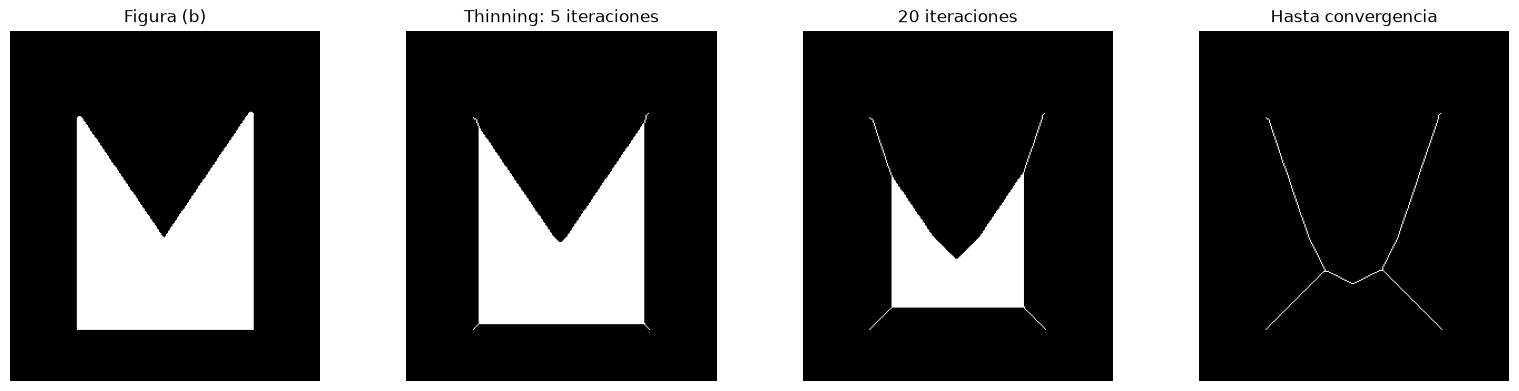

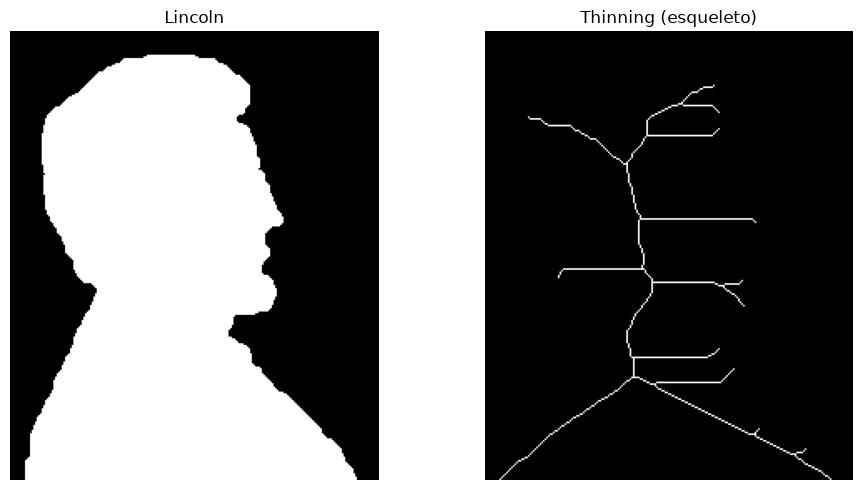

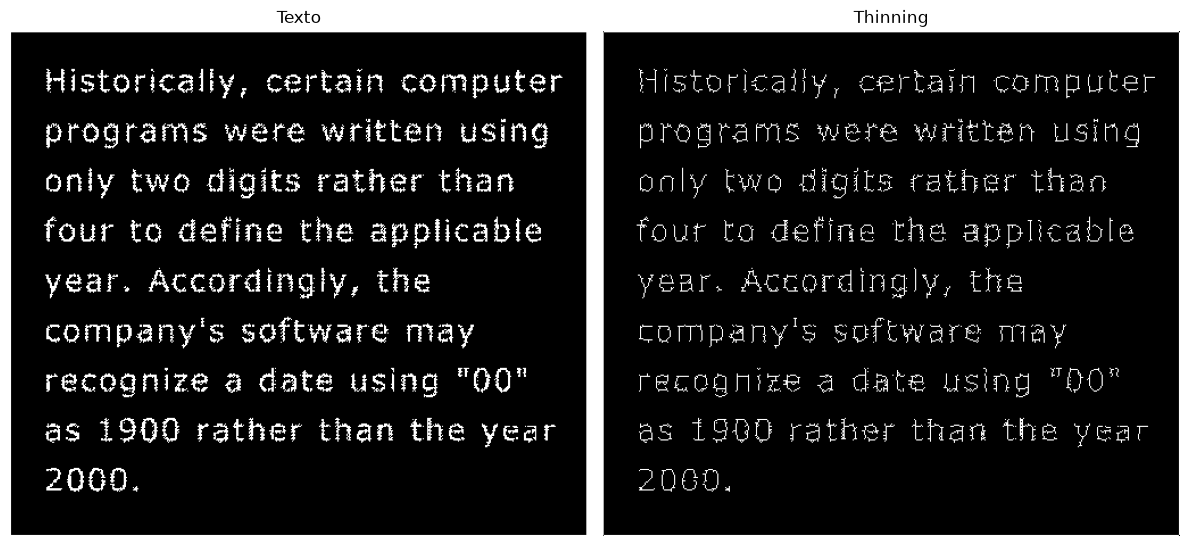

In [61]:
fig_b = np.array(Image.open("figure_b.bmp").convert("L")) > 127
lincoln = np.array(Image.open("Lincoln from penny.tif"))
text = np.array(Image.open("Broken_Text.tif"))

show_row([fig_b, thinning(fig_b, 5), thinning(fig_b, 20), thinning(fig_b)],
         ["Figura (b)", "Thinning: 5 iteraciones", "20 iteraciones", "Hasta convergencia"])
show_row([lincoln, thinning(lincoln)], ["Lincoln", "Thinning (esqueleto)"], size=5)
show_row([text, thinning(text)], ["Texto", "Thinning"], size=6)

## b) Thickening

El *thickening* es la operación dual del thinning: agrega al objeto los píxeles de fondo que coinciden con el patrón:

$$A \odot B = A \cup (A \circledast B)$$

usando los mismos elementos estructurales con los unos y ceros intercambiados. En la práctica se implementa haciendo thinning del fondo y complementando el resultado:

$$\text{thickening}(A) = \left[\text{thinning}(A^c)\right]^c$$

La diferencia con la dilatación es que el thickening conserva la topología del fondo: los objetos crecen pero nunca se unen entre sí ni se cierran sus agujeros. Si se itera hasta convergencia, el fondo queda reducido a líneas de 1 píxel que separan las regiones de influencia de cada objeto, algo útil para segmentar objetos que están muy cerca.

In [62]:
def thickening(image, max_iter=None):
    A = np.asarray(image) > 0
    return ~thinning(~A, max_iter)

**Ejemplo 1:** el texto del punto 1 engrosado 2 iteraciones, comparado con dilatar 2 veces con el mismo elemento en cruz. Con la dilatación hay letras que se pegan entre sí; con el thickening crecen sin tocarse. (Como el texto está "roto", los fragmentos de una misma letra también se mantienen separados: el thickening no sirve para reconectar texto, para eso es mejor la dilatación o el cierre.)

**Ejemplo 2:** thickening hasta convergencia de los cuadrados del punto 2: lo que queda del fondo son las fronteras entre las zonas de influencia de cada cuadrado.

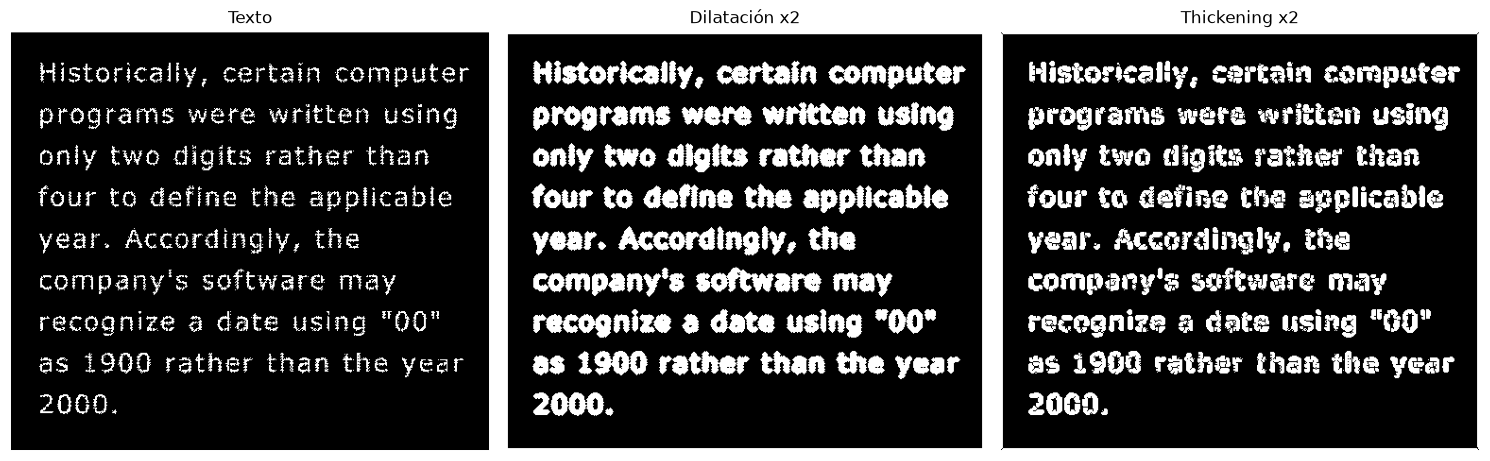

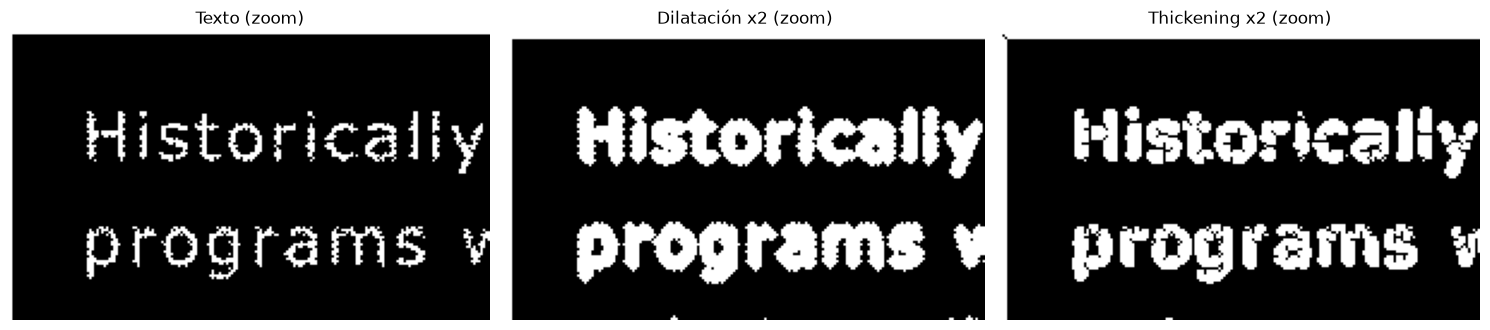

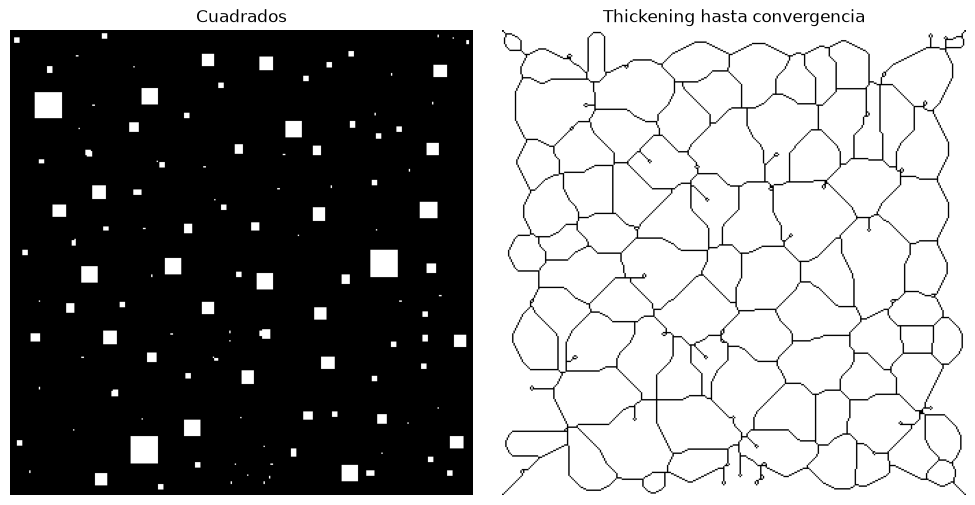

In [63]:
cross = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]])
text_dilated = gray_dilate(gray_dilate(text, cross), cross)
text_thick = thickening(text, 2)
show_row([text, text_dilated, text_thick],
         ["Texto", "Dilatación x2", "Thickening x2"], size=5)

zoom = (slice(0, 120), slice(0, 200))
show_row([text[zoom], text_dilated[zoom], text_thick[zoom]],
         ["Texto (zoom)", "Dilatación x2 (zoom)", "Thickening x2 (zoom)"], size=5)

show_row([squares, thickening(squares)], ["Cuadrados", "Thickening hasta convergencia"], size=5)

## c) Transformada top-hat

La transformada *top-hat* se usa sobre todo en escala de grises y extrae los detalles que son más chicos que el elemento estructural:

- **White top-hat** (top-hat): $T_w(f) = f - (f \circ b)$. La apertura elimina los objetos claros más chicos que $b$; restándola de la imagen quedan solo esos objetos claros pequeños.
- **Black top-hat** (bottom-hat): $T_b(f) = (f \bullet b) - f$. El cierre rellena los detalles oscuros más chicos que $b$; la diferencia los extrae.

Su uso clásico es **corregir iluminación no uniforme**: si el fondo varía lentamente, la apertura con un elemento grande es una estimación del fondo, y al restarla quedan los objetos sobre un fondo plano, que luego se pueden umbralizar con un único umbral global.

In [64]:
def white_top_hat(image, se):
    f = np.asarray(image).astype(np.int32)
    return f - gray_open(f, se)

def black_top_hat(image, se):
    f = np.asarray(image).astype(np.int32)
    return gray_close(f, se) - f

**Ejemplo 1 (radiografía de tórax):** en `tophat.tiff` las costillas, clavículas y vasos son estructuras claras y finas sobre un fondo cuya intensidad varía mucho (mediastino claro, pulmones oscuros, bordes negros). Con un disco de radio 10:

- La **apertura** borra todo lo claro más angosto que el disco y deja una estimación del fondo.
- El **white top-hat** ($f - f \circ b$) deja solo las estructuras claras finas: costillas, clavículas y vasos, independientemente de qué tan claro sea el fondo en cada zona.
- El **black top-hat** ($f \bullet b - f$) deja los detalles oscuros finos: los espacios entre costillas y la trama pulmonar.
- Combinándolos, $f + T_w - T_b$, se obtiene un realce de contraste: los detalles claros se aclaran y los oscuros se oscurecen, lo que hace más visible la estructura de los pulmones.

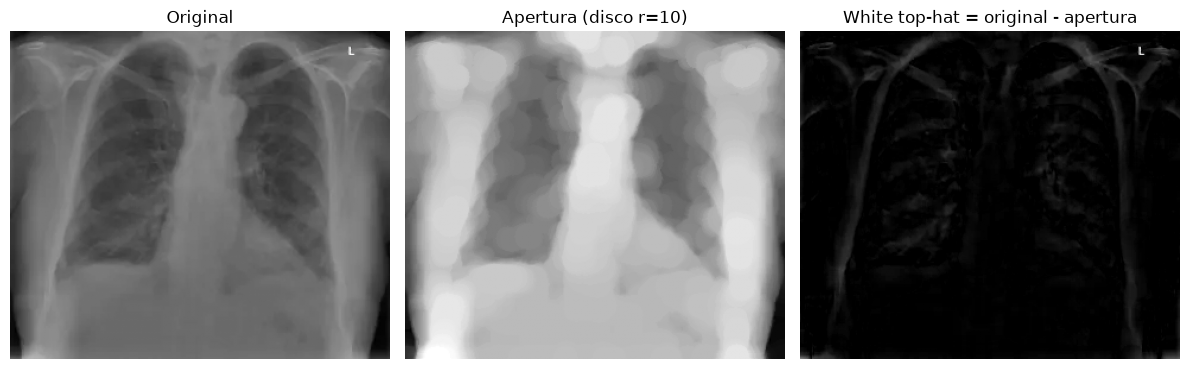

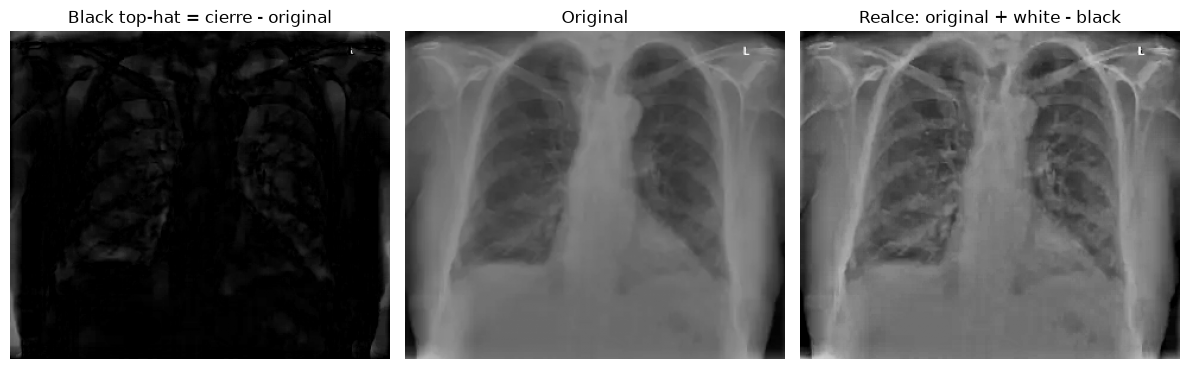

In [65]:
xray = np.array(Image.open("tophat.tiff").convert("L")).astype(np.int32)   # RGBA -> grayscale
disk10 = create_circle_struct_elem(10)

xray_open = gray_open(xray, disk10)
xray_white = white_top_hat(xray, disk10)
xray_black = black_top_hat(xray, disk10)
xray_enhanced = np.clip(xray + xray_white - xray_black, 0, 255)

show_row([xray, xray_open, xray_white],
         ["Original", "Apertura (disco r=10)", "White top-hat = original - apertura"])
show_row([xray_black, xray, xray_enhanced],
         ["Black top-hat = cierre - original", "Original", "Realce: original + white - black"])

**Ejemplo 2 (iluminación no uniforme):** se arma una imagen en grises con los cuadrados (brillo 80) sobre un fondo con un gradiente de iluminación, más un poco de ruido. Un umbral global no puede separarlos: o se pierden los cuadrados de la zona oscura, o se incluye el fondo de la zona clara. El white top-hat con un disco de radio 12 (mayor que el cuadrado más grande, de 20x20 en el archivo) estima y elimina el fondo, y después el mismo umbral funciona en toda la imagen.

El black top-hat se muestra sobre la imagen invertida (cuadrados oscuros sobre fondo claro): extrae los objetos oscuros.

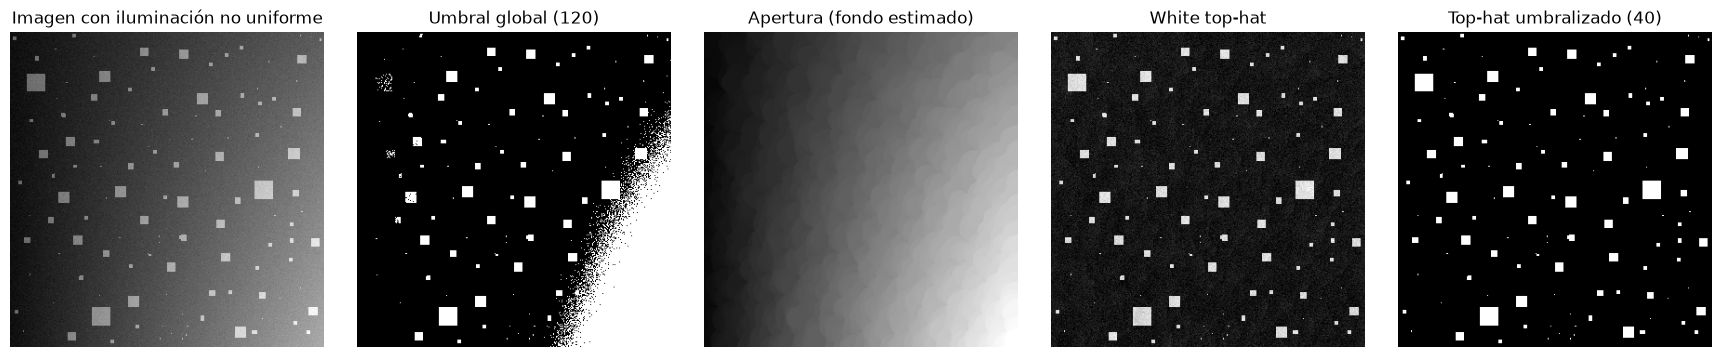

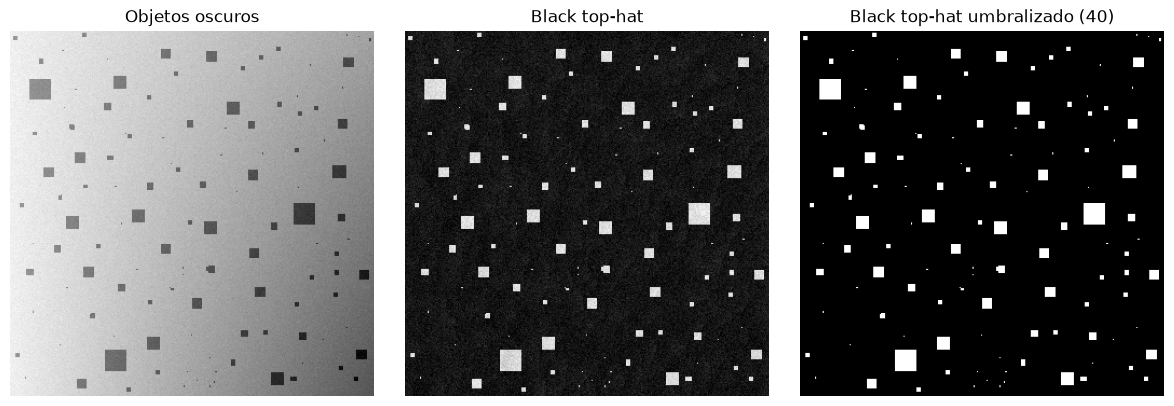

In [66]:
rng = np.random.default_rng(0)
h, w = squares.shape
yy, xx = np.mgrid[0:h, 0:w]
illumination = 30 + 140 * (xx / w) * (0.5 + 0.5 * yy / h)      # uneven background
gray = illumination + 80 * squares + rng.normal(0, 4, squares.shape)
gray = np.clip(gray, 0, 255).astype(np.uint8)

disk = create_circle_struct_elem(12)
background = gray_open(gray, disk)
tophat = white_top_hat(gray, disk)

threshold = 120
show_row([gray, gray > threshold, background, tophat, tophat > 40],
         ["Imagen con iluminación no uniforme", f"Umbral global ({threshold})",
          "Apertura (fondo estimado)", "White top-hat", "Top-hat umbralizado (40)"], size=3.5)

dark = 255 - gray
show_row([dark, black_top_hat(dark, disk), black_top_hat(dark, disk) > 40],
         ["Objetos oscuros", "Black top-hat", "Black top-hat umbralizado (40)"])